# Q2(e)

Let $d_t=|L_t-r_t|$. Use
$$D=a\sum_{t=0}^{23}d_t^2+b\left[d_0^2+d_{23}^2+\sum_{t=1}^{23}(d_t+d_{t-1})^2\right].$$
Base case: $a=0.5$, $b=0.25$ DKK/kWh$^2$. Two separate 1 kWh deviations cost 2 DKK; consecutive ones cost 2.5 DKK. The endpoint terms give isolated deviations the same cost at every hour. There is no link across midnight.

Minimize procurement cost plus $D$, using $d_t\ge L_t-r_t$ and $d_t\ge r_t-L_t$. This is a convex QP, but the hours no longer solve independently.


In [7]:
from pathlib import Path
from dataclasses import replace
import gurobipy as gp
from gurobipy import GRB
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data_loader import load_question

D = load_question('Q2_quadratic')
cL = load_question('Q2_linear').linear_disutility
T = range(24)
out = Path('results/Q2_temporal')
(out / 'original_hourly').mkdir(parents=True, exist_ok=True)
kinds = ['Linear', 'Quadratic', 'Coupled']
print('Two separated 1 kWh deviations:', 2 * (0.5 + 2 * 0.25), 'DKK')
print('Two consecutive 1 kWh deviations:', 2 * (0.5 + 2 * 0.25) + 2 * 0.25, 'DKK')


Two separated 1 kWh deviations: 2.0 DKK
Two consecutive 1 kWh deviations: 2.5 DKK


In [8]:
def solve(D, kind, c=1, a=0.5, b=0.25):
    m = gp.Model('flexible_consumer')
    m.Params.OutputFlag = 0
    m.Params.BarConvTol = 1e-10
    m.Params.QCPDual = 1
    r = D.reference_load
    buy = D.energy_price + D.import_tariff
    sell = D.energy_price - D.export_tariff

    # create variables
    p_imp = m.addVars(T, lb=-GRB.INFINITY, name='import')
    p_exp = m.addVars(T, lb=-GRB.INFINITY, name='export')
    p_pv = m.addVars(T, lb=-GRB.INFINITY, name='pv')
    L = m.addVars(T, lb=-GRB.INFINITY, name='load')

    cost = gp.quicksum(buy[t]*p_imp[t] - sell[t]*p_exp[t] + D.pv_marginal_cost*p_pv[t] for t in T)
    m.setObjective(cost, GRB.MINIMIZE)

    # add power balance and limits
    C = {}
    C['balance'] = m.addConstrs((L[t] + p_exp[t] - p_pv[t] - p_imp[t] == 0 for t in T), name='balance')
    C['load_min'] = m.addConstrs((L[t] >= D.load_min_kWh for t in T), name='load_min')
    C['load_max'] = m.addConstrs((L[t] <= D.load_max_kWh for t in T), name='load_max')
    C['pv_min'] = m.addConstrs((p_pv[t] >= 0 for t in T), name='pv_min')
    C['pv_max'] = m.addConstrs((p_pv[t] <= D.pv_available[t] for t in T), name='pv_max')
    C['import_min'] = m.addConstrs((p_imp[t] >= 0 for t in T), name='import_min')
    C['export_min'] = m.addConstrs((p_exp[t] >= 0 for t in T), name='export_min')

    m.update()
    if kind == 'Quadratic':
        penalty = c * gp.quicksum((L[t] - r[t])**2 for t in T)
    else:
        d = m.addVars(T, lb=0, name='absolute_deviation')
        C['deviation_positive'] = m.addConstrs((d[t] >= L[t] - r[t] for t in T), name='deviation_positive')
        C['deviation_negative'] = m.addConstrs((d[t] >= r[t] - L[t] for t in T), name='deviation_negative')
        if kind == 'Linear':
            penalty = c * gp.quicksum(d[t] for t in T)
        else:
            # add temporal penalty
            penalty = a * gp.quicksum(d[t]**2 for t in T)
            penalty += b * (d[0]**2 + d[23]**2 + gp.quicksum((d[t] + d[t-1])**2 for t in range(1,24)))

    # solve model
    m.setObjective(m.getObjective() + penalty, GRB.MINIMIZE)
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f'Gurobi status: {m.Status}')

    h = pd.DataFrame({'price': D.energy_price, 'pv_available': D.pv_available, 'reference_load': r})
    for name, v in [('import', p_imp), ('export', p_exp), ('pv', p_pv), ('load', L)]:
        h[name] = [v[t].X for t in T]
    if kind != 'Quadratic':
        h['absolute_deviation'] = [d[t].X for t in T]
    for name, con in C.items():
        h['dual_' + name] = [con[t].Pi for t in T]
    h.index.name = 'hour'

    # calculate daily results
    d = np.abs(h['load'].to_numpy() - r)
    cost = float((buy*h['import'] - sell*h['export'] + D.pv_marginal_cost*h['pv']).sum())
    if kind == 'Linear':
        penalty = c * d.sum()
    elif kind == 'Quadratic':
        penalty = c * (d**2).sum()
    else:
        penalty = a*(d**2).sum() + b*((d[1:]+d[:-1])**2).sum() + b*(d[0]**2+d[-1]**2)
    ref_cost = 0
    for t in T:
        if D.pv_marginal_cost <= sell[t]:
            pv = D.pv_available[t]
        elif D.pv_marginal_cost <= buy[t]:
            pv = min(r[t], D.pv_available[t])
        else:
            pv = 0
        ref_cost += D.pv_marginal_cost*pv + buy[t]*max(r[t]-pv,0) - sell[t]*max(pv-r[t],0)
    bound = np.isclose(h['load'], D.load_min_kWh, atol=1e-5, rtol=0) | np.isclose(h['load'], D.load_max_kWh, atol=1e-5, rtol=0)
    row = {'Procurement [DKK]': cost, 'Disutility [DKK]': float(penalty),
           'Objective [DKK]': m.ObjVal, 'Surplus [DKK]': -m.ObjVal,
           'Gain vs reference [DKK]': ref_cost-m.ObjVal,
           'Energy [kWh]': h['load'].sum(), 'Abs deviation [kWh]': d.sum(),
           'Max hourly deviation [kWh]': d.max(),
           'Adjacent deviation product [kWh^2]': float(np.dot(d[:-1],d[1:])),
           'Binding bound hours': int(bound.sum()), 'Off-reference hours': int((d>1e-5).sum())}
    m.dispose()
    return h, row


### Original data
Linear base: cL = 1.43. Quadratic base: cQ = 1. The other coefficients are from the earlier sweeps. Prices, PV and load limits are unchanged.


,Case,Procurement [DKK],Disutility [DKK],Objective [DKK],Energy [kWh],Abs deviation [kWh],Max hourly deviation [kWh],Adjacent deviation product [kWh^2],Binding bound hours
0,Linear base,31.1010,13.2132,44.3142,23.100,9.240,2.700,13.6908,11
1,Quadratic base,32.5445,7.4266,39.9710,22.765,9.575,1.050,7.1316,13
2,Coupled base,37.1877,5.2225,42.4102,25.628,6.712,0.708,3.3391,13
3,Linear cL=0.2,-1.4700,6.4680,4.9980,0.000,32.340,4.800,106.5384,24
4,Linear cL=0.5,-1.4700,16.1700,14.7000,0.000,32.340,4.800,106.5384,24
5,Linear cL=4,48.2160,0.0000,48.2160,32.340,0.000,0.000,0.0000,10
6,Quadratic cQ=0.05,-1.4700,5.5237,4.0537,0.000,32.340,4.800,106.5384,24
7,Quadratic cQ=0.5,20.8510,12.3349,33.1859,15.540,16.800,2.000,23.6738,15
8,Quadratic cQ=5,44.4757,1.8221,46.2979,30.110,2.230,0.210,0.3428,11


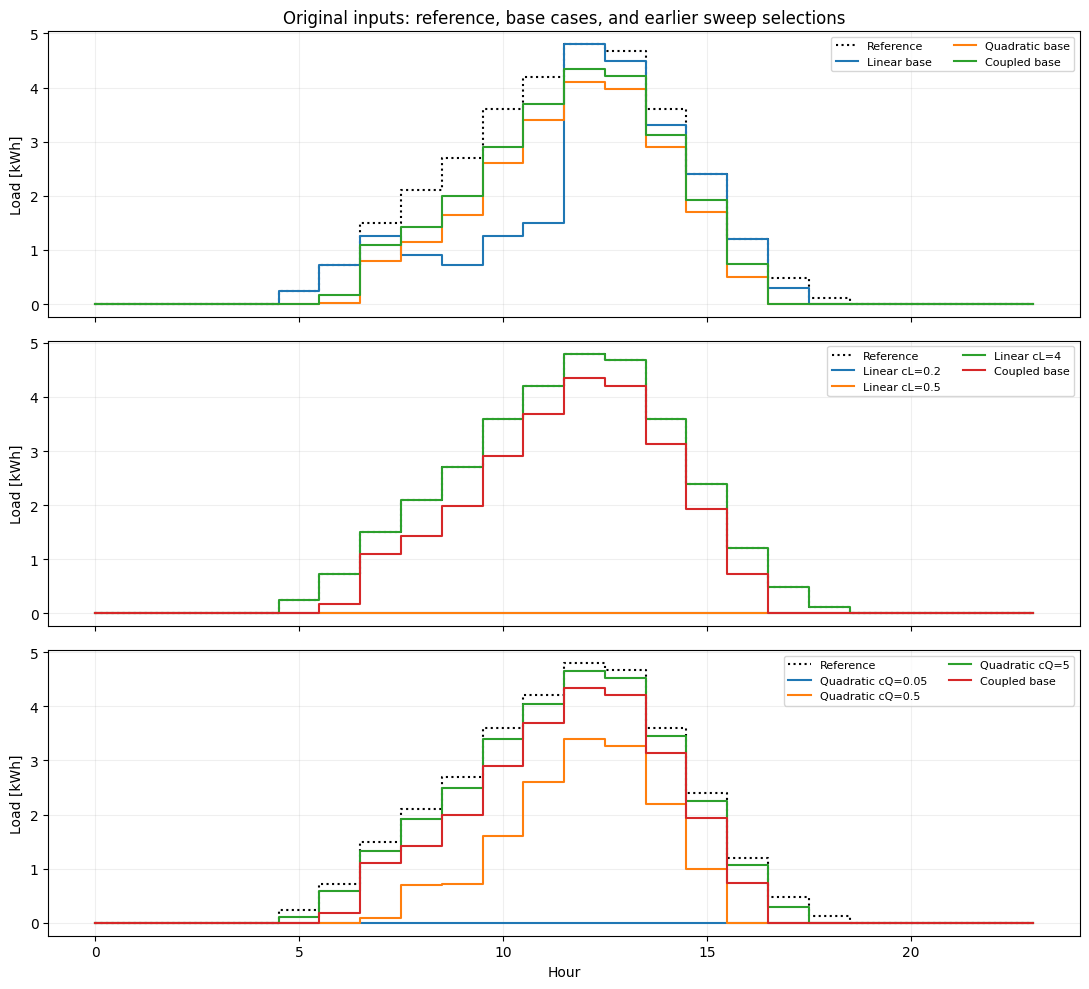

,Reference,Linear base deviation,Quadratic base deviation,Coupled base deviation
Hour,,,,
0,0.00,0.00,0.000,0.000
1,0.00,0.00,0.000,0.000
2,0.00,0.00,0.000,0.000
3,0.00,0.00,0.000,0.000
4,0.00,0.00,0.000,0.000
5,0.24,0.00,-0.240,-0.240
6,0.72,0.00,-0.705,-0.545
7,1.50,-0.24,-0.705,-0.401
8,2.10,-1.20,-0.950,-0.673


In [9]:
cases = [('Linear base', 'Linear', cL),
         ('Quadratic base', 'Quadratic', D.quadratic_disutility),
         ('Coupled base', 'Coupled', 1),
         ('Linear cL=0.2', 'Linear', 0.2),
         ('Linear cL=0.5', 'Linear', 0.5),
         ('Linear cL=4', 'Linear', 4),
         ('Quadratic cQ=0.05', 'Quadratic', 0.05),
         ('Quadratic cQ=0.5', 'Quadratic', 0.5),
         ('Quadratic cQ=5', 'Quadratic', 5)]
rows, hourly_rows, profiles = [], [], {}
for i, (label, kind, c) in enumerate(cases):
    h, row = solve(D, kind, c)
    rows.append({'Case': label, 'Model': kind, 'Coefficient': c if kind != 'Coupled' else np.nan,
                 'a': 0.5 if kind == 'Coupled' else np.nan,
                 'b': 0.25 if kind == 'Coupled' else np.nan, **row})
    profiles[label] = h.copy()
    stem = f'{D.question}_{i}_{kind.lower()}'
    h.to_csv(out / 'original_hourly' / (stem + '_hourly.csv'), index_label='hour')
    (out / 'original_hourly' / (stem + '_summary.txt')).write_text(
        f"status    : OPTIMAL\nobjective : {row['Objective [DKK]']:.4f} DKK\n")
    h['Case'], h['hour'] = label, D.hours
    h['deviation'] = h['load'] - D.reference_load
    hourly_rows.append(h)
original = pd.DataFrame(rows)
original.to_csv(out / 'original_metrics.csv', index=False)
pd.concat(hourly_rows, ignore_index=True).to_csv(out / 'original_profiles.csv', index=False)
cols = ['Case', 'Procurement [DKK]', 'Disutility [DKK]', 'Objective [DKK]',
        'Energy [kWh]', 'Abs deviation [kWh]', 'Max hourly deviation [kWh]',
        'Adjacent deviation product [kWh^2]', 'Binding bound hours']
display(original[cols].round(4))

# plot result
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
groups = [['Linear base', 'Quadratic base', 'Coupled base'],
          ['Linear cL=0.2', 'Linear cL=0.5', 'Linear cL=4', 'Coupled base'],
          ['Quadratic cQ=0.05', 'Quadratic cQ=0.5', 'Quadratic cQ=5', 'Coupled base']]
for ax, group in zip(axes, groups):
    ax.step(D.hours, D.reference_load, where='mid', color='black', linestyle=':', label='Reference')
    for label in group:
        ax.step(D.hours, profiles[label]['load'], where='mid', label=label)
    ax.set_ylabel('Load [kWh]')
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.2)
axes[0].set_title('Original inputs: reference, base cases, and earlier sweep selections')
axes[-1].set_xlabel('Hour')
fig.tight_layout()
fig.savefig(out / 'original_profiles.png', dpi=180)
plt.show()

hourly_comparison = pd.DataFrame({'Reference': D.reference_load})
for label in ['Linear base', 'Quadratic base', 'Coupled base']:
    hourly_comparison[label + ' deviation'] = profiles[label]['load'].to_numpy() - D.reference_load
hourly_comparison.index.name = 'Hour'
display(hourly_comparison.round(3))


### Price order
Flat reference 1.3475 kWh and no PV. Both profiles contain twelve prices of 0.85 and twelve of 2.50 DKK/kWh. Average all 24 shifts to avoid favouring a starting hour.

Here $c^L=c^Q=1.43$, $a=0.715$, $b=0.3575$: an isolated 1 kWh deviation costs 1.43 DKK in all models. Keep these values fixed between profiles. Surplus is $-\text{procurement}-\text{disutility}$, with reference utility set to zero. The common-surplus columns evaluate all schedules using the coupled penalty.


In [10]:
c, a, b = cL, cL/2, cL/4
base = replace(D, reference_load=np.full(24, D.reference_load.mean()),
               pv_available=np.zeros(24), pv_profile=np.zeros(24))
low, high = float(D.energy_price.min()), float(D.energy_price.max())
patterns = {'Alternating': np.tile([low, high], 12),
            'Six-hour blocks': np.tile(np.r_[np.full(6, low), np.full(6, high)], 2)}
rows, hourly_rows, example = [], [], {}
for pattern, prices in patterns.items():
    for phase in range(24):
        data = replace(base, energy_price=np.roll(prices, phase))
        for kind in kinds:
            h, row = solve(data, kind, c, a, b)
            row = {'Pattern': pattern, 'Phase': phase, 'Model': kind, **row}
            d = np.abs(h['load'].to_numpy() - data.reference_load)
            penalty = a*(d**2).sum() + b*(((d[1:]+d[:-1])**2).sum() + d[0]**2 + d[-1]**2)
            common = row['Procurement [DKK]'] + penalty
            ref_cost = ((data.energy_price + data.import_tariff)*data.reference_load).sum()
            row['Common coupled surplus [DKK]'] = -common
            row['Common coupled gain [DKK]'] = ref_cost - common
            row['Mean deviation high [kWh]'] = d[data.energy_price == high].mean()
            row['Mean deviation low [kWh]'] = d[data.energy_price == low].mean()
            rows.append(row)
            if phase == 0:
                example[pattern, kind] = h.copy()
            h['Pattern'], h['Phase'], h['Model'], h['hour'] = pattern, phase, kind, data.hours
            hourly_rows.append(h)
all_phases = pd.DataFrame(rows)
cols = [col for col in all_phases.select_dtypes('number') if col != 'Phase']
mean_results = all_phases.groupby(['Pattern', 'Model'], sort=False)[cols].mean().reset_index()
all_phases.to_csv(out / 'price_order_all_phases.csv', index=False)
mean_results.to_csv(out / 'price_order_mean.csv', index=False)
pd.concat(hourly_rows, ignore_index=True).to_csv(out / 'price_order_hourly.csv', index=False)
cols = ['Pattern', 'Model', 'Surplus [DKK]', 'Gain vs reference [DKK]',
        'Energy [kWh]', 'Abs deviation [kWh]',
        'Mean deviation high [kWh]', 'Mean deviation low [kWh]']
display(mean_results[cols].round(4))


,Pattern,Model,Surplus [DKK],Gain vs reference [DKK],Energy [kWh],Abs deviation [kWh],Mean deviation high [kWh],Mean deviation low [kWh]
0,Alternating,Linear,-44.9526,25.3869,16.1700,16.1700,1.3475,0.0000
1,Alternating,Quadratic,-47.6350,22.7045,14.0883,18.2517,1.0490,0.4720
2,Alternating,Coupled,-51.3912,18.9483,19.5848,12.7552,1.0443,0.0186
3,Six-hour blocks,Linear,-44.9526,25.3869,16.1700,16.1700,1.3475,0.0000
4,Six-hour blocks,Quadratic,-47.6350,22.7045,14.0883,18.2517,1.0490,0.4720
5,Six-hour blocks,Coupled,-54.5816,15.7579,19.9579,12.3821,0.7475,0.2844


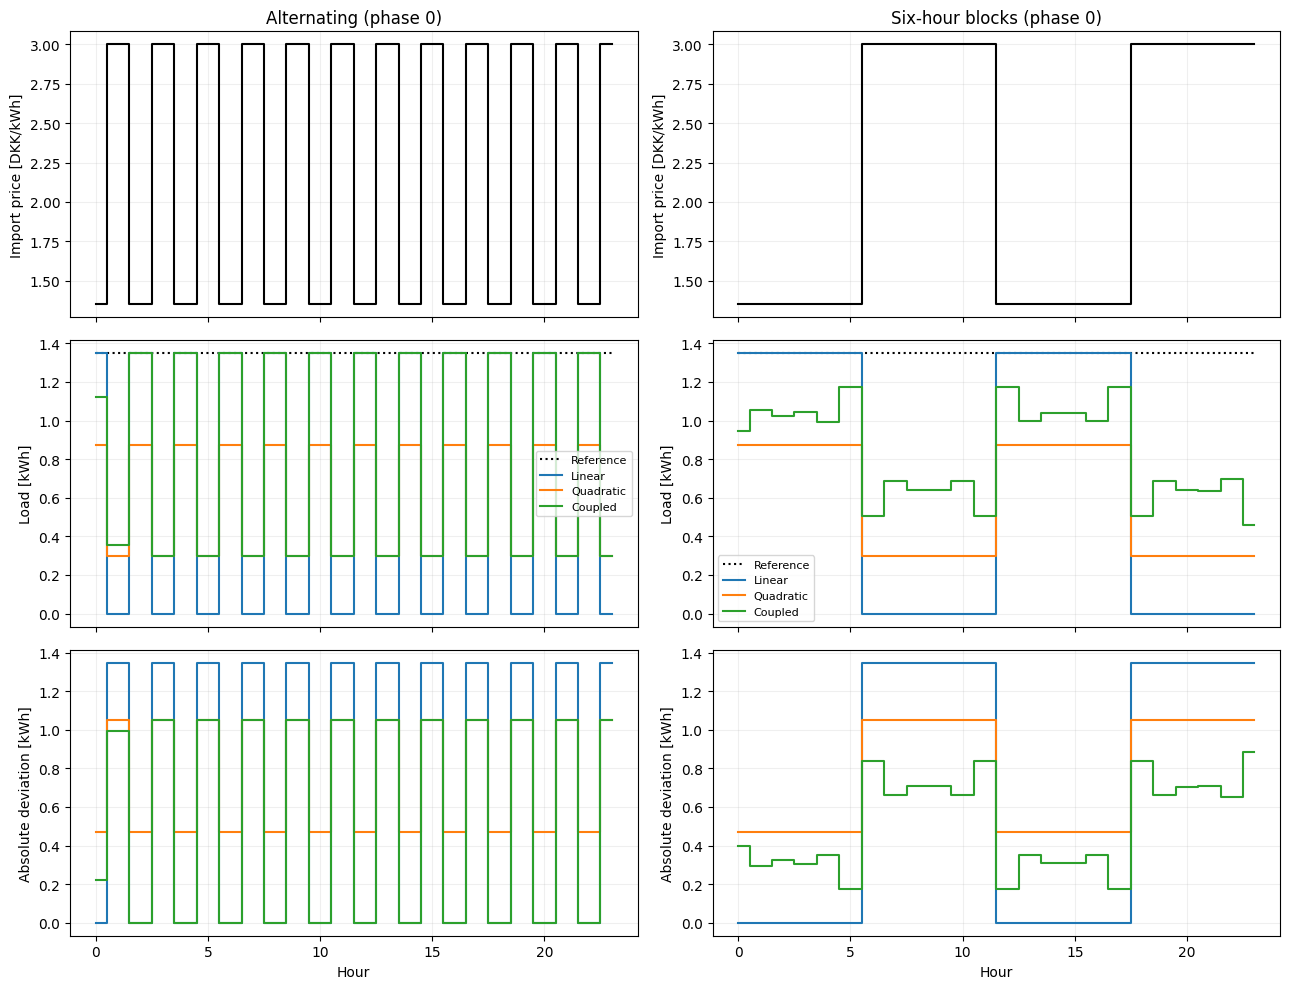

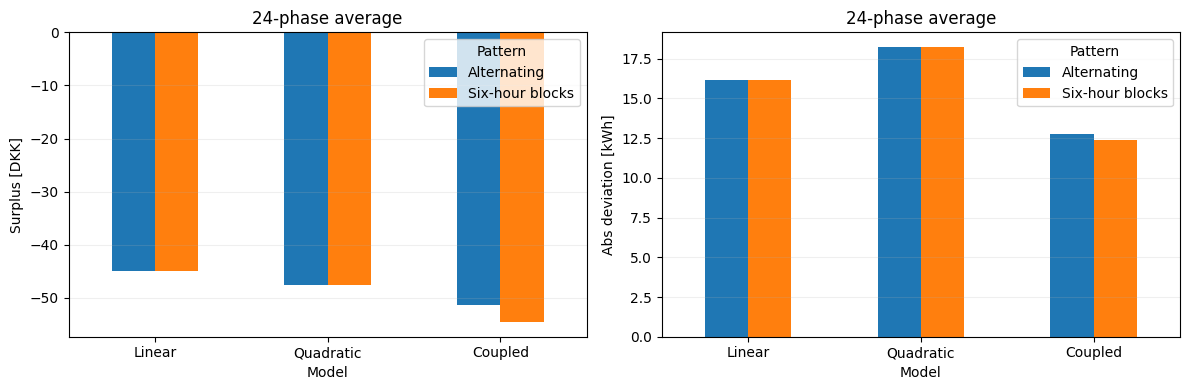

,Pattern,Model,Common coupled surplus [DKK],Common coupled gain [DKK]
0,Alternating,Linear,-52.9879,17.3516
1,Alternating,Quadratic,-55.7774,14.5621
2,Alternating,Coupled,-51.3912,18.9483
3,Six-hour blocks,Linear,-65.4296,4.9099
4,Six-hour blocks,Quadratic,-58.0581,12.2814
5,Six-hour blocks,Coupled,-54.5816,15.7579


Saved tables and figures: C:\Users\Saads\Documents\Saad\Uni\Masters\Semester 3\Optimization in modern power systems\Assignment 1\46750-assignment-1-group-19\results\Q2_temporal


In [11]:
# plot result
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
for col, pattern in enumerate(patterns):
    axes[0, col].step(base.hours, patterns[pattern] + base.import_tariff, where='mid', color='black')
    axes[0, col].set(title=pattern + ' (phase 0)', ylabel='Import price [DKK/kWh]')
    axes[1, col].step(base.hours, base.reference_load, where='mid', color='black', linestyle=':', label='Reference')
    for kind in kinds:
        h = example[pattern, kind]
        axes[1, col].step(base.hours, h['load'], where='mid', label=kind)
        axes[2, col].step(base.hours, np.abs(h['load'] - base.reference_load), where='mid', label=kind)
    axes[1, col].set_ylabel('Load [kWh]')
    axes[1, col].legend(fontsize=8)
    axes[2, col].set(xlabel='Hour', ylabel='Absolute deviation [kWh]')
    for ax in axes[:, col]:
        ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(out / 'price_order_profiles.png', dpi=180)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['Surplus [DKK]', 'Abs deviation [kWh]']):
    mean_results.pivot(index='Model', columns='Pattern', values=metric).reindex(kinds).plot.bar(ax=ax, rot=0)
    ax.set_ylabel(metric)
    ax.set_title('24-phase average')
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(out / 'price_order_metrics.png', dpi=180)
plt.show()
display(mean_results[['Pattern', 'Model', 'Common coupled surplus [DKK]', 'Common coupled gain [DKK]']].round(4))
print('Saved tables and figures:', out.resolve())


The coupled base deviates by 6.712 kWh, compared with 9.240 (linear) and 9.575 (quadratic). It reduces the sustained deviations in hours 5-18.

Price order does not change the separable models' daily results. For the coupled model, high-price blocks reduce surplus by 3.1903 DKK/day: it keeps more consumption during expensive runs to avoid prolonged discomfort. Raw surpluses across different preference functions are not a welfare ranking.
